# 04 · Drift detection and scenarios

**Goal.** Build and check the two pieces the retraining experiment needs from this part:

1. **Drift detection** (`src/drift.py`): PSI and KS per feature and per window, with customer/history features and economic indicators monitored **separately**, plus the proposed drift-trigger rule.
2. **Scenarios** (`src/scenarios.py`): the four data streams every strategy runs on (real replay, stationary, sudden shift, gradual shift).

**Settings used** (all in `src/settings.py`, marked *PROPOSED, pending team approval*): 8 stream windows of ~1,030 rows, PSI with 10 quantile bins and a 1e-4 floor, retrain when any model-input feature has **PSI > 0.25**.

**What this notebook does not do:** it trains no model and makes no claim about performance. An alert means *the inputs changed*, not *predictions got worse*; that is checked in the experiment notebook.

**Data rule:** the alert threshold is checked on training and development rows only. Stream rows appear only in section 4, where they are measured, never used to choose anything.

In [1]:
import sys; sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import chronological_split, encode_target, load_dataset
from src.drift import drift_over_windows, false_alarm_rate, null_psi_distribution
from src.scenarios import all_scenarios, split_into_windows
from src.settings import (MONITOR_GROUPS, N_STREAM_WINDOWS, PSI_ALERT, SEED, SEEDS, SHIFT_FEATURE,
                          SYNTHETIC_WINDOW_ROWS, TRIGGER_GROUPS)

pd.set_option('display.width', 160)
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#1f2430', '#6b7280', '#e5e7eb'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'axes.axisbelow': True, 'axes.titlelocation': 'left',
                     'axes.titleweight': 'bold', 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

df = load_dataset()
train, dev, stream = chronological_split(df)
print('train / dev / stream rows:', len(train), len(dev), len(stream))
print('Monitored groups:', {g: len(f) for g, f in MONITOR_GROUPS.items()}, '| trigger groups:', TRIGGER_GROUPS)

train / dev / stream rows: 24712 8238 8238
Monitored groups: {'customer_history': 10, 'economic': 5} | trigger groups: ['customer_history']


## 1. How often does the rule fire when nothing has changed?

We take 200 random samples of 1,030 rows **from the training rows themselves** and compare each with all training rows. Nothing has changed, so every PSI value here is pure sampling noise. The share of samples where the rule would still fire is the rule's **false-alarm rate per window**.

In [2]:
null = null_psi_distribution(train, window_rows=SYNTHETIC_WINDOW_ROWS, n_draws=200, seed=SEED)
null_table = (null.groupby(['group', 'feature'])['psi']
              .quantile([0.5, 0.95, 0.99, 1.0]).unstack()
              .set_axis(['median', '95th pct', '99th pct', 'max'], axis=1).round(3))
display(null_table)
print(f'False-alarm rate of "PSI > {PSI_ALERT}" (trigger groups):', false_alarm_rate(null))
print(f'Same rule on economic indicators only:', false_alarm_rate(null, trigger_groups=['economic']))
print('Largest no-change PSI of any feature:', round(null['psi'].max(), 3))

median  95th pct  99th pct    max
group            feature                                          
customer_history age              0.008     0.015     0.019  0.020
                 default          0.001     0.005     0.007  0.008
                 education        0.005     0.012     0.014  0.015
                 housing          0.001     0.006     0.011  0.016
                 job              0.010     0.019     0.023  0.025
                 loan             0.001     0.006     0.009  0.010
                 marital          0.002     0.008     0.012  0.020
                 pdays            0.000     0.002     0.004  0.005
                 poutcome         0.001     0.005     0.008  0.019
                 previous         0.000     0.003     0.007  0.020
economic         cons.conf.idx    0.004     0.012     0.015  0.019
                 cons.price.idx   0.004     0.012     0.015  0.019
                 emp.var.rate     0.001     0.006     0.009  0.011
                 euribor3m        0.008     0.016     0.021  0.026
                 nr.employed      0.001     0.006     0.009  0.011

False-alarm rate of "PSI > 0.25" (trigger groups): 0.0
Same rule on economic indicators only: 0.0
Largest no-change PSI of any feature: 0.026


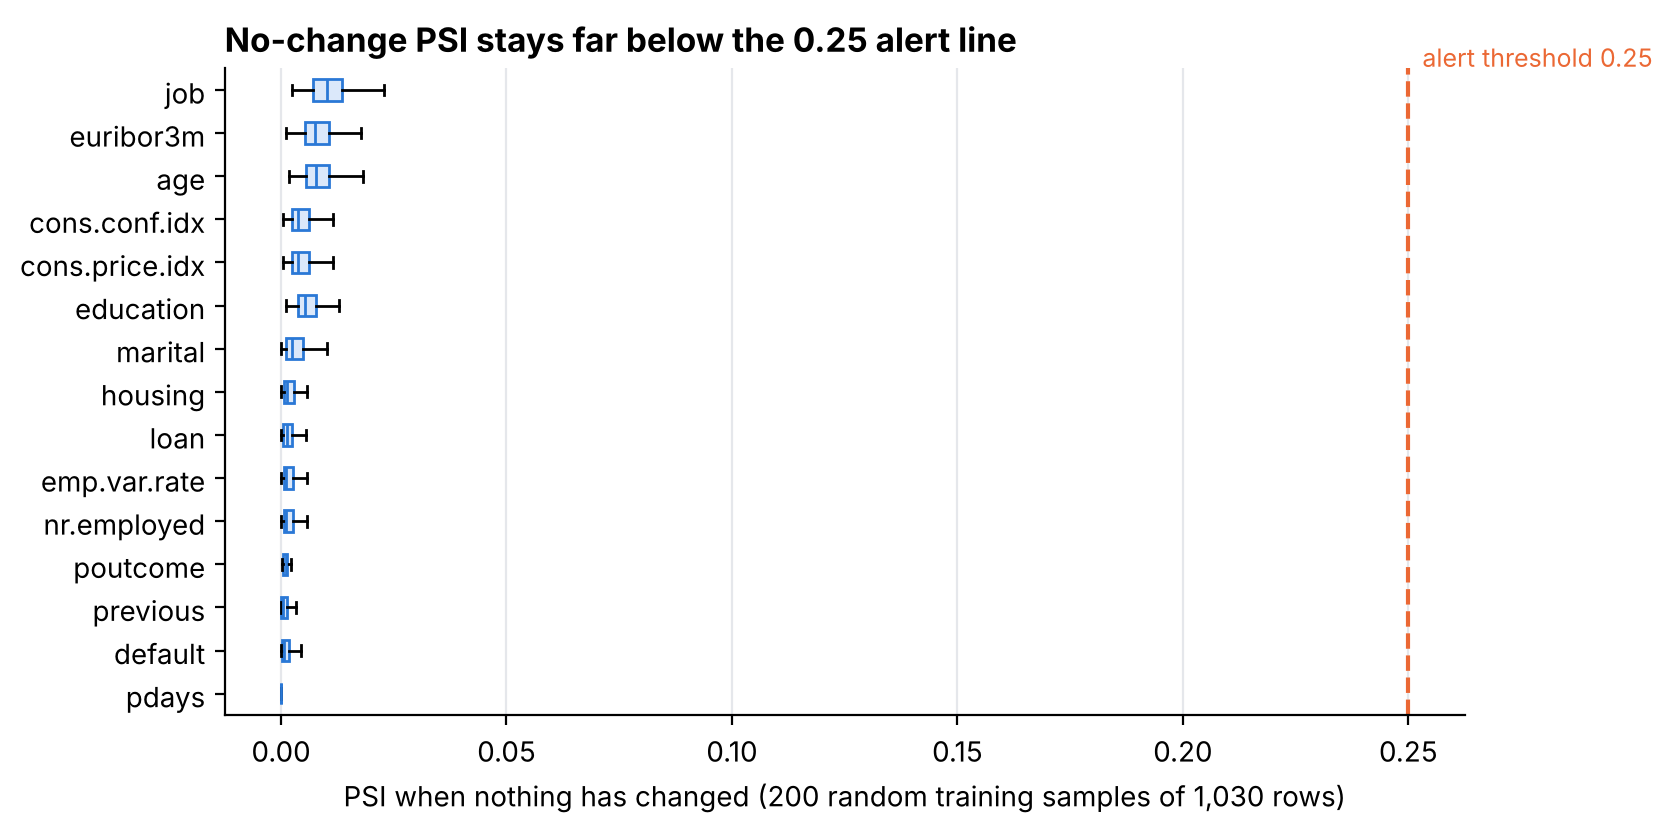

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
order = null.groupby('feature')['psi'].quantile(0.99).sort_values().index
data = [null.loc[null['feature'] == f, 'psi'] for f in order]
ax.boxplot(data, orientation='horizontal', tick_labels=order, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor='#dbe8fa', color=BLUE), medianprops=dict(color=BLUE))
ax.axvline(PSI_ALERT, color=ORANGE, ls='--', lw=1.5)
ax.text(PSI_ALERT, len(order) + 0.4, f'  alert threshold {PSI_ALERT}', color=ORANGE, va='bottom', fontsize=9)
ax.set_xlabel('PSI when nothing has changed (200 random training samples of 1,030 rows)')
ax.set_title('No-change PSI stays far below the 0.25 alert line')
ax.grid(axis='y', visible=False)
fig.savefig('../figures/10_null_psi_calibration.png'); plt.show()

## 2. Does the rule notice real change? (development rows, allowed for checking)

Development rows come after the training rows in time. We cut them into 8 windows and compare each with the training rows.

In [4]:
dev_windows = split_into_windows(dev, N_STREAM_WINDOWS)
dev_drift = drift_over_windows(train, dev_windows)
dev_table = dev_drift.pivot_table(index=['group', 'feature'], columns='window', values='psi').round(2)
display(dev_table)
fired = dev_drift[dev_drift['group'].isin(TRIGGER_GROUPS) & dev_drift['alert']]
print('Trigger-group features above 0.25, per window:')
print(fired.groupby('window')['feature'].apply(list).to_string())

window                               1      2      3      4      5      6      7      8
group            feature                                                               
customer_history age              0.42   0.70   0.09   0.09   0.08   0.06   0.15   0.15
                 default          0.20   0.23   0.16   0.16   0.04   0.25   0.02   0.03
                 education        0.08   0.08   0.14   0.02   0.03   0.02   0.10   0.12
                 housing          0.01   0.03   0.04   0.04   0.01   0.04   0.02   0.01
                 job              0.22   0.19   0.22   0.15   0.15   0.16   0.21   0.23
                 loan             0.00   0.01   0.01   0.00   0.00   0.00   0.00   0.00
                 marital          0.01   0.01   0.03   0.04   0.01   0.03   0.01   0.03
                 pdays            0.03   0.04   0.02   0.05   0.03   0.34   0.07   0.05
                 poutcome         0.88   0.70   0.65   1.02   1.21   1.08   1.63   1.58
                 previous         0.88   0.70   0.65   1.04   1.21   1.02   1.63   1.58
economic         cons.conf.idx   11.14  11.14  11.40  16.50  16.95  16.26  16.95  16.95
                 cons.price.idx  11.14  11.14  11.40  16.50  16.95  16.26  16.95  16.95
                 emp.var.rate    11.74  11.74  12.02  17.68  17.68  17.68  17.68  17.68
                 euribor3m        9.24   9.24   9.24   9.24   9.24   9.24   9.24   9.24
                 nr.employed     11.74  11.74  12.02  17.68  17.68  17.68  17.68  17.68

Trigger-group features above 0.25, per window:
window
1      [age, previous, poutcome]
2      [age, previous, poutcome]
3           [previous, poutcome]
4           [previous, poutcome]
5           [previous, poutcome]
6    [pdays, previous, poutcome]
7           [previous, poutcome]
8           [previous, poutcome]


## 3. Scenarios: does each one contain the change it should?

For every scenario we compare each window with the rows the initial model is fitted on (`initial_train`), which is what the drift-triggered strategy does before any retrain. For the trigger group we keep the **largest** PSI per window; economic indicators are shown separately.

In [5]:
rows = []
for seed in SEEDS:
    for sc in all_scenarios(df, seed=seed):
        if sc.kind == 'real' and seed != SEEDS[0]:
            continue                                  # the real replay does not depend on the seed
        drift = drift_over_windows(sc.initial_train, sc.windows)
        for window, part in drift.groupby('window'):
            trig = part[part['group'].isin(TRIGGER_GROUPS)]
            econ = part[part['group'] == 'economic']
            rows.append({'scenario': sc.name, 'seed': seed, 'window': window,
                         'change_window': None if sc.change_window is None else sc.change_window + 1,
                         'max_trigger_psi': trig['psi'].max(),
                         'top_feature': trig.loc[trig['psi'].idxmax(), 'feature'],
                         'trigger_fires': bool(trig['alert'].any()),
                         'max_economic_psi': econ['psi'].max(),
                         'yes_rate': encode_target(sc.windows[window - 1]).mean()})
scenario_drift = pd.DataFrame(rows)
display(scenario_drift[scenario_drift['seed'] == SEEDS[0]]
        .pivot(index='scenario', columns='window', values='max_trigger_psi').round(2)
        .loc[['real_replay', 'stationary', 'sudden', 'gradual']])

window,1,2,3,4,5,6,7,8
scenario,,,,,,,,
real_replay,1.59,1.40,1.15,1.25,2.19,2.65,3.77,3.96
stationary,0.02,0.01,0.01,0.02,0.02,0.02,0.03,0.02
sudden,0.02,0.01,0.01,0.02,0.98,1.06,0.93,1.13
gradual,0.02,0.01,0.07,0.18,0.41,0.64,1.13,0.92


In [6]:
def first_alert(part):
    hits = part.loc[part['trigger_fires'], 'window']
    return int(hits.min()) if len(hits) else None

summary = []
for (name, seed), part in scenario_drift.groupby(['scenario', 'seed']):
    change = part['change_window'].iloc[0]
    if name == 'real_replay':                  # no known change point: alerts are not "false" or "true"
        false_alarms, alert = None, None
    elif pd.isna(change):                      # stationary: every alert is a false alarm
        false_alarms, alert = int(part['trigger_fires'].sum()), None
    else:
        false_alarms = int(part.loc[part['window'] < change, 'trigger_fires'].sum())
        alert = first_alert(part[part['window'] >= change])
    summary.append({'scenario': name, 'seed': seed,
                    'change at window': None if pd.isna(change) else int(change),
                    'false alarms': false_alarms,
                    'first alert at/after change': alert,
                    'detection delay (windows)': None if (alert is None or pd.isna(change)) else alert - int(change),
                    'windows with an alert': int(part['trigger_fires'].sum())})
summary = pd.DataFrame(summary).set_index(['scenario', 'seed']).loc[['real_replay', 'stationary', 'sudden', 'gradual']]
display(summary)

change at window  false alarms  first alert at/after change  detection delay (windows)  windows with an alert
scenario    seed                                                                                                               
real_replay 42                 NaN           NaN                          NaN                        NaN                      8
stationary  42                 NaN           0.0                          NaN                        NaN                      0
            43                 NaN           0.0                          NaN                        NaN                      0
            44                 NaN           0.0                          NaN                        NaN                      0
sudden      42                 5.0           0.0                          5.0                        0.0                      4
            43                 5.0           0.0                          5.0                        0.0                      4
            44                 5.0           0.0                          5.0                        0.0                      4
gradual     42                 3.0           0.0                          5.0                        2.0                      4
            43                 3.0           0.0                          5.0                        2.0                      4
            44                 3.0           0.0                          5.0                        2.0                      4

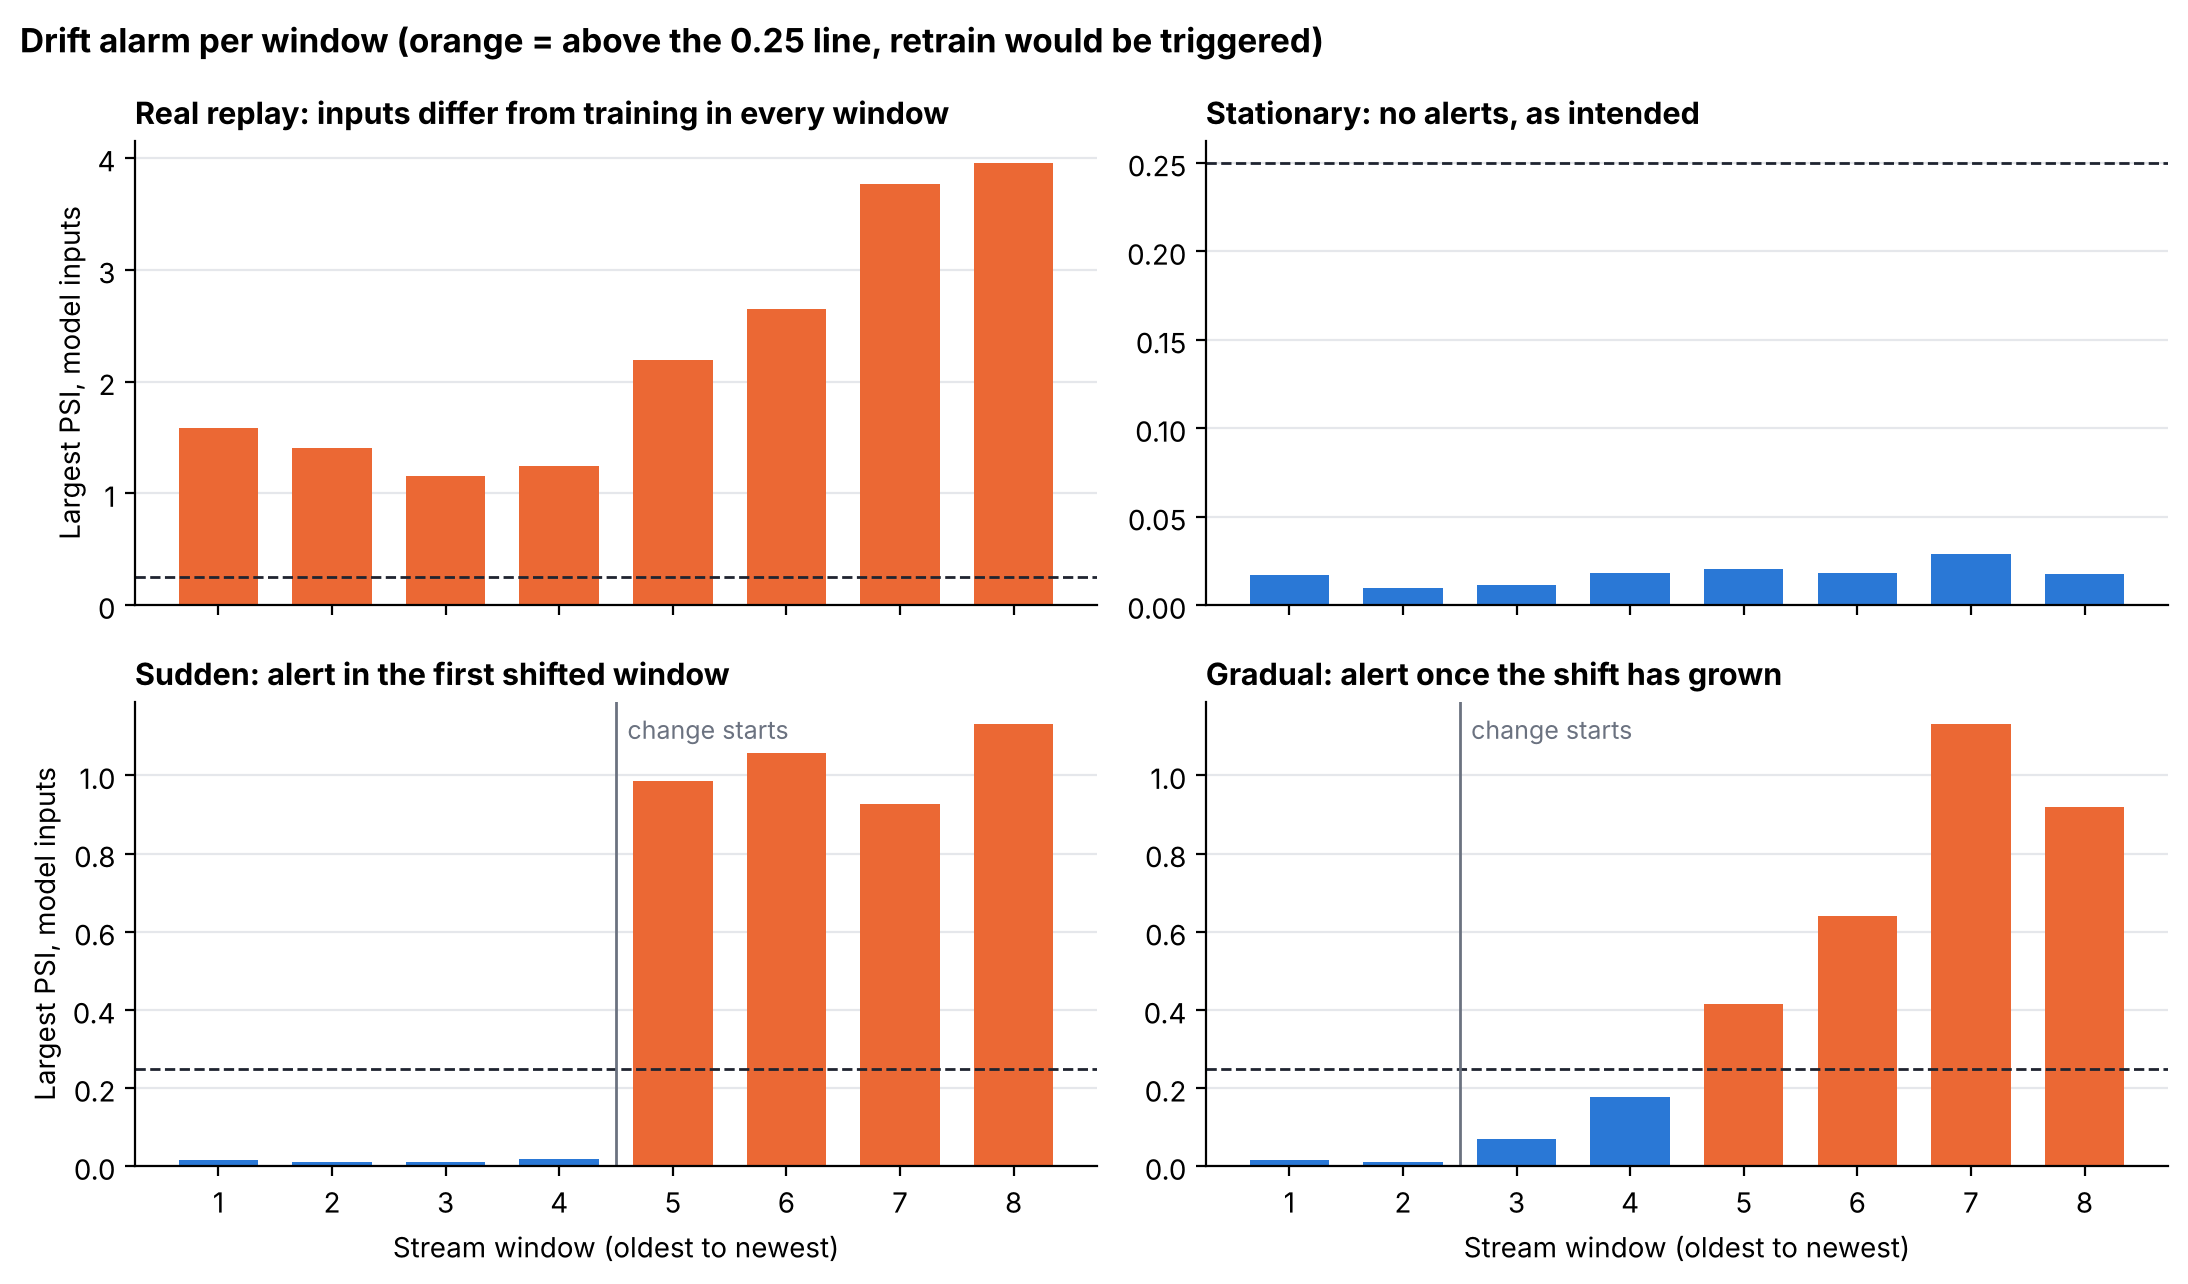

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
titles = {'real_replay': 'Real replay: inputs differ from training in every window',
          'stationary': 'Stationary: no alerts, as intended',
          'sudden': 'Sudden: alert in the first shifted window',
          'gradual': 'Gradual: alert once the shift has grown'}
seed0 = scenario_drift[scenario_drift['seed'] == SEEDS[0]]
for ax, name in zip(axes.ravel(), ['real_replay', 'stationary', 'sudden', 'gradual']):
    part = seed0[seed0['scenario'] == name]
    colors = [ORANGE if f else BLUE for f in part['trigger_fires']]
    ax.bar(part['window'], part['max_trigger_psi'], color=colors, width=0.7)
    ax.axhline(PSI_ALERT, color=INK, ls='--', lw=1)
    change = part['change_window'].iloc[0]
    if not pd.isna(change):
        ax.axvline(change - 0.5, color=MUTED, lw=1)
        ax.text(change - 0.4, ax.get_ylim()[1] * 0.92, 'change starts', color=MUTED, fontsize=9)
    ax.set_title(titles[name], fontsize=11)
    ax.set_xticks(range(1, N_STREAM_WINDOWS + 1))
    ax.grid(axis='x', visible=False)
for ax in axes[1]: ax.set_xlabel('Stream window (oldest to newest)')
for ax in axes[:, 0]: ax.set_ylabel('Largest PSI, model inputs')
fig.suptitle('Drift alarm per window (orange = above the 0.25 line, retrain would be triggered)', x=0.01,
             ha='left', fontweight='bold')
fig.tight_layout(); fig.savefig('../figures/11_scenario_drift_alarm.png'); plt.show()

## 4. Real replay: which features move, by group

The real stream compared with the training rows. Economic indicators are shown apart from the model inputs: they shift far more, but they are not model features in the current baseline, so they do not trigger retraining (`TRIGGER_GROUPS`).

window                               1      2      3      4      5      6      7      8
group            feature                                                               
customer_history age              0.20   0.39   0.10   0.27   0.37   0.47   0.38   0.38
                 default          0.05   0.09   0.20   0.73   0.64   0.69   0.68   0.81
                 education        0.16   0.11   0.08   0.26   0.23   0.13   0.19   0.22
                 housing          0.03   0.02   0.03   0.02   0.01   0.01   0.02   0.01
                 job              0.17   0.21   0.07   0.42   0.94   0.79   0.63   0.81
                 loan             0.00   0.00   0.00   0.00   0.00   0.00   0.00   0.01
                 marital          0.09   0.13   0.13   0.19   0.04   0.02   0.14   0.13
                 pdays            0.06   0.06   0.14   0.58   1.13   1.47   2.13   2.41
                 poutcome         1.59   1.40   1.15   1.25   2.19   2.65   3.77   3.96
                 previous         1.58   1.40   1.14   1.12   2.05   2.52   3.63   3.90
economic         cons.conf.idx   16.95  16.95  16.95  16.13  16.27  15.77  15.35  15.38
                 cons.price.idx  16.95  16.95  16.95  16.13  16.27  15.77  15.35  15.38
                 emp.var.rate    17.68  17.68  17.68  17.20  17.17  17.23  17.00  17.01
                 euribor3m        9.24   9.24   9.24   9.24   9.24   9.24   9.24   9.24
                 nr.employed     17.68  17.68  17.68  17.20  17.17  17.23  17.00  17.01

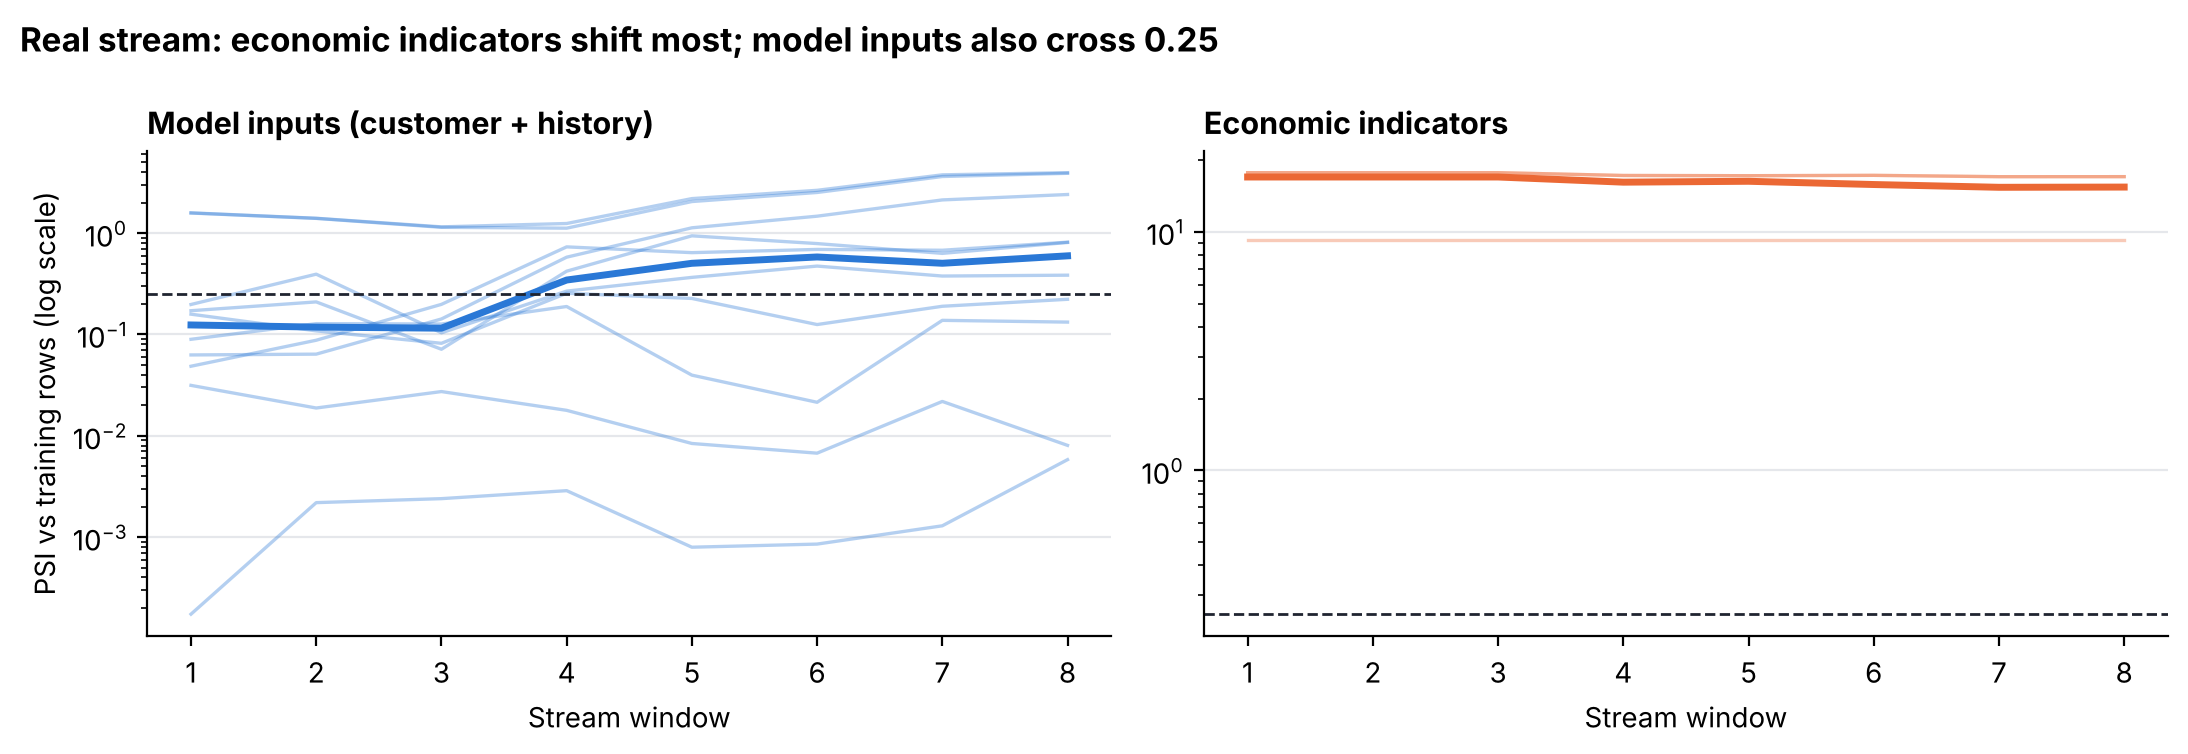

In [8]:
real = all_scenarios(df, seed=SEED)[0]
real_drift = drift_over_windows(real.initial_train, real.windows)
display(real_drift.pivot_table(index=['group', 'feature'], columns='window', values='psi').round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, group, color in zip(axes, ['customer_history', 'economic'], [BLUE, ORANGE]):
    part = real_drift[real_drift['group'] == group].pivot(index='window', columns='feature', values='psi')
    for feature in part.columns:
        ax.plot(part.index, part[feature], lw=1.2, color=color, alpha=0.35)
    ax.plot(part.index, part.median(axis=1), lw=2.5, color=color, label='median feature')
    ax.axhline(PSI_ALERT, color=INK, ls='--', lw=1)
    ax.set_yscale('log'); ax.set_xticks(range(1, N_STREAM_WINDOWS + 1))
    ax.set_xlabel('Stream window'); ax.grid(axis='x', visible=False)
axes[0].set_title('Model inputs (customer + history)', fontsize=11); axes[0].set_ylabel('PSI vs training rows (log scale)')
axes[1].set_title('Economic indicators', fontsize=11)
fig.suptitle('Real stream: economic indicators shift most; model inputs also cross 0.25', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout(); fig.savefig('../figures/12_real_replay_drift_by_group.png'); plt.show()

## 5. Summary

Numbers below are printed from this run; the text interprets them.

In [9]:
s0 = summary.xs(SEEDS[0], level='seed')
print(f"1. No-change false-alarm rate of PSI > {PSI_ALERT}: {false_alarm_rate(null):.3f} "
      f"(largest no-change PSI {null['psi'].max():.3f}).")
print(f"2. Stationary scenario: {int(summary.loc['stationary', 'windows with an alert'].sum())} alerts "
      f"across {len(SEEDS)} seeds x {N_STREAM_WINDOWS} windows.")
for name in ['sudden', 'gradual']:
    delays = summary.loc[name, 'detection delay (windows)'].tolist()
    print(f"3. {name}: detection delay per seed = {delays}; false alarms before change = "
          f"{summary.loc[name, 'false alarms'].tolist()}.")
print(f"4. Real replay: trigger fires in {int(s0.loc['real_replay', 'windows with an alert'])} of {N_STREAM_WINDOWS} "
      f"windows against the training rows.")
yes = scenario_drift[scenario_drift['seed'] == SEEDS[0]].groupby('scenario')['yes_rate'].agg(['min', 'max']).round(3)
print('5. Yes-rate range per scenario (seed 42):'); print(yes.to_string())

1. No-change false-alarm rate of PSI > 0.25: 0.000 (largest no-change PSI 0.026).
2. Stationary scenario: 0 alerts across 3 seeds x 8 windows.
3. sudden: detection delay per seed = [0.0, 0.0, 0.0]; false alarms before change = [0.0, 0.0, 0.0].
3. gradual: detection delay per seed = [2.0, 2.0, 2.0]; false alarms before change = [0.0, 0.0, 0.0].
4. Real replay: trigger fires in 8 of 8 windows against the training rows.
5. Yes-rate range per scenario (seed 42):
               min    max
scenario                 
gradual      0.037  0.051
real_replay  0.073  0.542
stationary   0.034  0.052
sudden       0.040  0.054


**Reading the results**

- The 0.25 rule practically never fires on sampling noise alone, so alerts in the synthetic scenarios come from the built-in shift, not from chance.
- Sudden and gradual shifts are detected; the gradual one only once it has grown, which is the expected detection delay.
- In the **real** stream, model inputs (mainly `previous` and `poutcome`, i.e. more repeat customers, and later `age` and `job`) differ from the training rows in every window, so a drift-triggered strategy compared against the original training rows would retrain often. After each retrain the reference becomes the new training rows, so how often it fires in the actual experiment depends on the strategy loop.
- The synthetic age shift barely changes the yes rate. These scenarios therefore test the point that **drift does not automatically mean worse predictions**; whether performance drops is measured in the experiment.

**Limits:** PSI depends on binning and the empty-bin floor; KS p-values are near zero for almost any difference at this sample size, so the KS statistic is reported as an effect size only. Synthetic scenarios are controlled experiments, not historical evidence. All thresholds and window settings are proposals pending team approval.